# Historical cloud execution record

Saved outputs from the November 2 cloud run. This record references private `/workspace/SNOOPPI/work/review_20261102` artifacts. **It is not the portable entry point.** Open [01_results.ipynb](../01_results.ipynb) for a public-data rerun, or [02_retrain.ipynb](../02_retrain.ipynb) for opt-in retraining. Raw verification cannot run from the public repository alone.

# SNOOPPI evidence audit and repeated-seed results

Fresh cloud execution, 2026-11-02. This notebook independently verifies each saved run before summarizing it. Macro-AP is the mean of positive-class and negative-class average precision. All comparisons are exploratory on the previously exposed benchmark. Feature-removal ablations also change head parameter counts. Three seeds measure training variation only; they do not create independent test sets.

## Findings from the completed run

- **45 classifier fits completed:** all 15 configurations at seeds 44, 45, and 46.
- **Independent checks passed:** 80,235 test predictions, 36 selected MLP epochs, source-row reconciliation, frozen artifact hashes, and fresh cluster/input isolation.
- **97 regression/integration tests passed** and all eight draft workflows completed on synthetic fixtures. Both historical record notebooks were replayed successfully.
- **ProtT5 + RF has the highest observed mean test macro-AP: 0.6189.** ESM-C is highest among full MLPs at 0.5997. Full ESM-2 MLP results vary substantially across these three seeds.
- The paired component-bootstrap ranges cross zero for both selected RF–MLP comparisons. They do **not establish superiority**. These are descriptive exploratory ranges on a previously exposed test set, not confirmatory inference.
- Train, validation, and test CSVs match the historical bytes exactly. The regenerated cluster mapping has a different hash; historical mapping identity is not established. All original CSV/cache hashes match.
- Historical seed-44 results are not numerically identical to this run. PyTorch stayed at 2.15.0+cpu; NumPy, pandas and scikit-learn versions changed. The version changes and score differences are recorded without attributing causality to a particular library.

The main chart was inspected directly for readability and labels. Full-page HTML visual inspection was blocked by browser policy. Independent confirmatory data and real mutation/interface annotations were not supplied; those scientific branches remain open. Unknown-pair mining was tested on synthetic fixtures and does not establish biological negative labels.


In [1]:
from pathlib import Path
import sys,json,hashlib,subprocess
import numpy as np,pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path('/workspace/SNOOPPI'); WORK=ROOT/'work/review_20261102'
sys.path[:0]=[str(ROOT/'experiments/cluster_disjoint'),str(ROOT/'drafting_code')]
from snooppi_utils import file_sha256, summarize_predictions, assert_model_ready, macro_average_precision
from snooppi_protocol import mapped_component_frame,mapped_overlap_report
from finish import input_isolation
plt.rcParams.update({'figure.figsize':(9,5),'font.size':11,'axes.spines.top':False,'axes.spines.right':False})


## Fresh validation receipts
The first combined pytest invocation failed during collection because the isolated experiment folders use repeated module names. The following individual commands are the completed replacements. Dry-run outputs are synthetic and have no biological interpretation.

In [2]:
receipts=[]
for name in ['validate_notebooks','validate_drafts','tests','cluster_tests','v1_tests','mmseqs_tests','smoke_drafts','smoke_mining']:
    record=json.loads((WORK/'logs'/f'{name}.json').read_text());record['name']=name;receipts.append(record)
    assert record['exit_code']==0,name
display(pd.DataFrame(receipts)[['name','exit_code','seconds']])
for name in ['tests','cluster_tests','v1_tests','mmseqs_tests']:
    print(name, (WORK/'logs'/f'{name}.log').read_text()[-600:])


,name,exit_code,seconds
0,validate_notebooks,0,1.167388
1,validate_drafts,0,1.218851
2,tests,0,24.325744
3,cluster_tests,0,1.618999
4,v1_tests,0,30.983344
5,mmseqs_tests,0,2.343194
6,smoke_drafts,0,46.385063
7,smoke_mining,0,14.333329


tests eline.py::test_notebook_protocol[False]
  01_classical_embedding_baselines.ipynb:9:4: UserWarning: Legacy ProtT5 cache has no encoder revision/preprocessing metadata; dimension and coverage will be checked.

tests/test_unknown_mining.py: 24 warnings
  /workspace/SNOOPPI/drafting_code/snooppi_mining.py:358: UserWarning: Legacy ProtT5 cache has no encoder revision/preprocessing metadata; dimension and coverage will be checked.
    cache, metadata = load_embedding_cache(Path(path), "ProtT5")

-- Docs: https://docs.pytest.org/en/stable/how-to/capture-warnings.html
69 passed, 30 warnings in 22.54s

cluster_tests Tests.test_assignment_keeps_components_and_both_classes) ... ok
test_both_partners_and_truncated_inputs_link_components (test_prepare.ProtocolTests.test_both_partners_and_truncated_inputs_link_components) ... ok
test_conflicting_reversed_pairs_and_invalid_inputs (test_prepare.ProtocolTests.test_conflicting_reversed_pairs_and_invalid_inputs) ... ok
test_edge_fallback_is_disjoin

## Verify real-data artifacts
Reconcile all source rows, verify frozen hashes, cluster isolation, ordered pair and label identities, prediction file hashes, metrics, and validation-selected epochs. The historical verifier hardcodes seed 44; the equivalent checks below explicitly support all three prespecified seeds.

In [3]:
manifest=json.loads((WORK/'split/manifest.json').read_text())
for name,h in manifest['files'].items(): assert file_sha256(WORK/'split'/name)==h,name
parts={s:pd.read_csv(WORK/'split'/f'{s}.csv') for s in ['train','validation','test']}
assert_model_ready(parts);assert not input_isolation(parts).overlap.any()
mapping=pd.read_csv(WORK/'split/mmseqs2_clusters.csv')
assert not mapped_overlap_report(parts,mapping,'cluster_id').overlapping_cluster_id.any()
rows=pd.concat([*parts.values(),pd.read_csv(WORK/'split/exclusions.csv'),pd.read_csv(WORK/'split/cross_partition_exclusions.csv')])
assert len(rows)==39003 and not rows[['original_split','source_row']].duplicated().any()
test=parts['test'];all_metrics=[];predictions={};checks=[]
for seed in [44,45,46]:
    out=WORK/f'seed{seed}';m=pd.read_csv(out/'metrics.csv')
    assert (out/'COMPLETE').exists() and len(m)==45 and set(m.seed)=={seed}
    assert len(list(out.glob('*_complete.json')))==15
    for row in m[m.split=='test'].itertuples():
        tag=f'{row.encoder}_{row.head}_{row.variant}';p=pd.read_csv(out/f'{tag}_test_predictions.csv')
        assert p.full_pair_id.tolist()==test.full_pair_id.tolist()
        assert np.array_equal(p.label,test.label)
        values=summarize_predictions(p.label,p.probability,row.threshold)
        for k,v in values.items():assert np.isclose(v,getattr(row,k)),(seed,tag,k)
        rec=json.loads((out/f'{tag}_complete.json').read_text())
        for name,h in rec['files'].items():assert file_sha256(out/name)==h
        if row.head=='mlp':
            h=pd.read_csv(out/f'{tag}_history.csv');assert h.loc[h.validation_macro_ap.idxmax(),'epoch']==row.best_epoch
        predictions[(seed,tag)]=p.probability.to_numpy()
    checks.append({'seed':seed,'fits':15,'test_predictions_verified':15*len(test),'selected_epochs_verified':12})
    all_metrics.append(m)
metrics=pd.concat(all_metrics,ignore_index=True)
metrics.to_csv(WORK/'all_metrics.csv',index=False)
(WORK/'fresh_verification.json').write_text(json.dumps(checks,indent=2))
display(pd.DataFrame(checks))


,seed,fits,test_predictions_verified,selected_epochs_verified
0,44,15,26745,12
1,45,15,26745,12
2,46,15,26745,12


## Training-seed variation
Dots represent individual seeds, not confidence intervals. All runs use the same test pairs. The constant prevalence control has macro-AP 0.5.

,mean,std,min,max
model,,,,
prott5 / rf / full,0.6189,0.0060,0.6123,0.6238
esmc / mlp / full,0.5997,0.0018,0.5977,0.6012
esmc / mlp / no_product,0.5989,0.0044,0.5939,0.6023
prott5 / mlp / no_absdiff,0.5951,0.0035,0.5911,0.5973
prott5 / mlp / full,0.5853,0.0047,0.5814,0.5906
prott5 / mlp / no_product,0.5836,0.0034,0.5797,0.5862
esm2 / rf / full,0.5806,0.0139,0.5707,0.5965
esmc / mlp / no_sum,0.5769,0.0027,0.5742,0.5796
esmc / rf / full,0.5748,0.0033,0.5717,0.5782


Full-feature heads, means across three seeds:


auroc  positive_ap  negative_ap  macro_ap  macro_f1     mcc  \
encoder head                                                                 
esm2    mlp   0.6125       0.9063       0.2110    0.5586    0.5599  0.1282   
        rf    0.6602       0.9309       0.2303    0.5806    0.5329  0.0915   
esmc    mlp   0.6948       0.9354       0.2640    0.5997    0.5745  0.1505   
        rf    0.6672       0.9317       0.2179    0.5748    0.5446  0.1021   
prott5  mlp   0.6652       0.9233       0.2473    0.5853    0.5817  0.1777   
        rf    0.7264       0.9456       0.2922    0.6189    0.5864  0.2087   

               brier  
encoder head          
esm2    mlp   0.2034  
        rf    0.1121  
esmc    mlp   0.1618  
        rf    0.1122  
prott5  mlp   0.2008  
        rf    0.1092

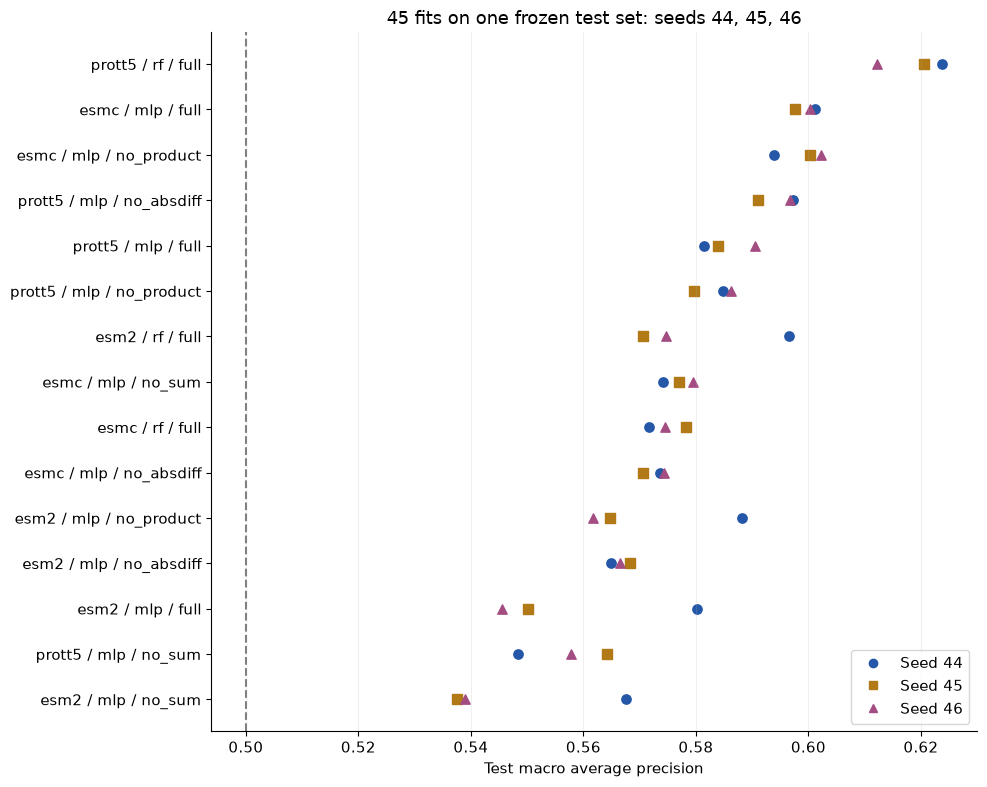

In [4]:
held=metrics[metrics.split=='test'].copy();held['model']=held.encoder+' / '+held['head']+' / '+held.variant
summary=held.groupby('model').macro_ap.agg(['mean','std','min','max']).sort_values('mean',ascending=False)
summary.to_csv(WORK/'seed_summary.csv');display(summary.round(4))
print('Full-feature heads, means across three seeds:')
display(held[held.variant=='full'].groupby(['encoder','head'])[['auroc','positive_ap','negative_ap','macro_ap','macro_f1','mcc','brier']].mean().round(4))
fig,ax=plt.subplots(figsize=(10,8))
for i,(label,row) in enumerate(summary.iterrows()):
    values=held[held.model==label].sort_values('seed')
    for marker,color,(_,v) in zip(['o','s','^'],['#2457A7','#B27A16','#A34D83'],values.iterrows()):ax.scatter(v.macro_ap,i,marker=marker,color=color,s=45)
ax.set_yticks(range(len(summary)),summary.index);ax.invert_yaxis();ax.axvline(.5,color='gray',linestyle='--')
ax.set_xlabel('Test macro average precision');ax.set_title('45 fits on one frozen test set: seeds 44, 45, 46')
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([],[],linestyle='',marker=marker,color=color,label=f'Seed {seed}') for seed,marker,color in zip([44,45,46],['o','s','^'],['#2457A7','#B27A16','#A34D83'])],loc='lower right')
ax.grid(axis='x',alpha=.2);fig.tight_layout();fig.savefig(WORK/'seed_comparison.png',dpi=160);plt.show()


## Historical seed-44 comparison
Same source and partition hashes do not guarantee identical floating-point training results across software versions. This table compares the fresh seed-44 test metrics with the original published run; package versions are preserved in each training manifest.

In [5]:
old=pd.read_csv(ROOT/'experiments/cluster_disjoint/results/metrics.csv')
joined=held[held.seed==44].merge(old[old.split=='test'],on=['encoder','head','variant'],suffixes=('_fresh','_historical'))
joined['macro_ap_delta']=joined.macro_ap_fresh-joined.macro_ap_historical
joined[['encoder','head','variant','macro_ap_historical','macro_ap_fresh','macro_ap_delta']].to_csv(WORK/'historical_comparison.csv',index=False)
display(joined[['encoder','head','variant','macro_ap_historical','macro_ap_fresh','macro_ap_delta']].round(6))
old_env=json.loads((ROOT/'experiments/cluster_disjoint/results/training_manifest.json').read_text())
new_env=json.loads((WORK/'seed44/manifest.json').read_text())
display(pd.DataFrame({'historical':{k:old_env[k] for k in ['torch','numpy','pandas','sklearn']},'fresh':{k:new_env[k] for k in ['torch','numpy','pandas','sklearn']}}))


,encoder,head,variant,macro_ap_historical,macro_ap_fresh,macro_ap_delta
0,prott5,rf,full,0.616751,0.623778,0.007027
1,prott5,mlp,full,0.581696,0.581407,-0.000289
2,prott5,mlp,no_sum,0.548438,0.548438,0.000000
3,prott5,mlp,no_absdiff,0.597235,0.597321,0.000085
4,prott5,mlp,no_product,0.585092,0.584816,-0.000276
5,esm2,rf,full,0.590152,0.596515,0.006363
6,esm2,mlp,full,0.580986,0.580226,-0.000760
7,esm2,mlp,no_sum,0.567145,0.567487,0.000342
8,esm2,mlp,no_absdiff,0.566922,0.564830,-0.002092
9,esm2,mlp,no_product,0.572534,0.588213,0.015679


,historical,fresh
torch,2.15.0+cpu,2.15.0+cpu
numpy,2.3.5,2.5.4
pandas,2.2.3,3.1.0
sklearn,1.8.0,1.9.1


## Dependence sensitivity
Rebuild interaction components within the test set. Removing the largest component changes the population; it is a sensitivity analysis, not a replacement score. This exposes how much the result depends on the dominant component.

In [6]:
grouped=mapped_component_frame(test,mapping,'cluster_id');groups=grouped.mapped_component.to_numpy();unique,counts=np.unique(groups,return_counts=True)
largest=unique[counts.argmax()];keep=groups!=largest
print('Components:',len(unique),'largest pairs:',counts.max(),'fraction:',counts.max()/len(test))
y=test.label.to_numpy();sensitivity=[]
for (seed,tag),prob in predictions.items():
    sensitivity.append({'seed':seed,'model':tag,'all_macro_ap':macro_average_precision(y,prob),'without_largest_macro_ap':macro_average_precision(y[keep],prob[keep])})
sensitivity=pd.DataFrame(sensitivity);sensitivity.to_csv(WORK/'component_sensitivity.csv',index=False)
display(sensitivity.groupby('model')[['all_macro_ap','without_largest_macro_ap']].mean().round(4))


Components: 214 largest pairs: 1212 fraction: 0.6797532249018509


,all_macro_ap,without_largest_macro_ap
model,,
esm2_mlp_full,0.5586,0.5338
esm2_mlp_no_absdiff,0.5665,0.5608
esm2_mlp_no_product,0.5716,0.5443
esm2_mlp_no_sum,0.5480,0.4742
esm2_rf_full,0.5806,0.5173
esmc_mlp_full,0.5997,0.5731
esmc_mlp_no_absdiff,0.5728,0.5703
esmc_mlp_no_product,0.5989,0.5745
esmc_mlp_no_sum,0.5769,0.5321


## Exploratory paired component resampling
Two comparisons were chosen from the prior October 30 report: ProtT5 RF versus ProtT5 full MLP, and ProtT5 RF versus ESM-C full MLP. Resample whole test interaction components with replacement, preserving model pairing and averaging differences across the same three training seeds. The 95% percentile ranges are descriptive conditional bootstrap ranges, not confirmatory significance evidence. A dominant component and only three seeds limit inference. No row-independent intervals or superiority claim is made.

In [7]:
rng=np.random.default_rng(20261102);members=[np.flatnonzero(groups==g) for g in unique]
comparisons=[('prott5_rf_full','prott5_mlp_full'),('prott5_rf_full','esmc_mlp_full')]
boot=[[] for _ in comparisons];invalid=0
for b in range(1000):
    idx=np.concatenate([members[j] for j in rng.integers(len(members),size=len(members))])
    if len(np.unique(y[idx]))<2:invalid+=1;continue
    for k,(left,right) in enumerate(comparisons):
        boot[k].append(np.mean([macro_average_precision(y[idx],predictions[(s,left)][idx])-macro_average_precision(y[idx],predictions[(s,right)][idx]) for s in [44,45,46]]))
rows=[]
for (left,right),values in zip(comparisons,boot):
    delta=np.mean([macro_average_precision(y,predictions[(s,left)])-macro_average_precision(y,predictions[(s,right)]) for s in [44,45,46]])
    low,high=np.quantile(values,[.025,.975]);rows.append(dict(comparison=left+' minus '+right,mean_delta=delta,bootstrap_low=low,bootstrap_high=high,valid_draws=len(values),invalid_draws=invalid))
intervals=pd.DataFrame(rows);intervals.to_csv(WORK/'exploratory_component_intervals.csv',index=False);display(intervals.round(4))


,comparison,mean_delta,bootstrap_low,bootstrap_high,valid_draws,invalid_draws
0,prott5_rf_full minus prott5_mlp_full,0.0336,-0.0062,0.1248,1000,0
1,prott5_rf_full minus esmc_mlp_full,0.0192,-0.0519,0.0486,1000,0


## Remaining evidence gaps
The original cache provenance limitation remains. No new PLM embeddings were computed. The historical benchmark is exploratory and excludes over half of cleaned pairs. Independent confirmatory data, verified negative labels for unknown pairs, and mutation/interface annotations remain necessary for those study branches. Synthetic successes do not fill these gaps. Full original optimizer state and validation-loss logs were never saved; they cannot be reconstructed from aggregate histories.